# Gamma/hadron
Simulated gammas against simulated protons: Hillas parameters with the same selection, mean scaled width and length,
reconstructed directions and shower cores, how well cuts and a BDT separate them, and the gammas' energy from a BDT regression, from
two already processed sim_telarray productions (run `process_sims.ipynb` on each first).

Everything is set in **Selection** below: pick a config per production, then override its telescopes or selection there to
compare selections. The histograms and profiles are made by the functions in **Plotting**.

Camera coordinates are sim_telarray's, fixed to the alt-az mount: +x towards higher altitude, +y towards lower azimuth.
`distance` and `alpha` are from the camera center (`process_simulation()`'s default `x`, `y`): the source position for
a point-like gamma production without a wobble.

# Imports

In [35]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.colors import LogNorm
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split

from heap import events as ev
from heap.config import local_simulation
from heap import process_simulation as ps
from heap.reconstruction import core_distances, reconstruct_cores, reconstruct_directions, tilted_frame, tilted_positions
from simulation_tools.run_simulation import load_config

# Selection

In [36]:
# one simulation config per production: configs/local.yaml's, or any other, e.g. Path("~/simulations/<name>.yaml")
GAMMA_CONFIG = local_simulation("gamma")
PROTON_CONFIG = local_simulation("proton")
SAMPLES = {"gamma": load_config(GAMMA_CONFIG), "proton": load_config(PROTON_CONFIG)}

# the spectral index each production is weighted to (dN/dE ~ E^index), None = as simulated;
# e.g. -2.7 for cosmic-ray protons, about -3 for the Crab at 10-100 TeV
SPECTRAL_INDEX = {"gamma": None, "proton": None}

# override any of these, e.g. TELESCOPES = ["T1", "T2", "T3"] or IMAGE_CUTS = {"width": ("value", 0.3)}
TELESCOPES = None # None = every telescope; "T<sim_telarray id>"
MIN_TEL = 2
MIN_NPIX = 3
IMAGE_CUTS = {} # {column: (mode, threshold)}, see heap.events.apply_cut(); "nsigma" thresholds are per production

# mean scaled width and length: the gammas' width and length in bins of these two columns
LOOKUP_X, LOOKUP_Y = "log10_size", "distance" # or LOOKUP_Y = "impact_reco"
LOOKUP_X_BINS = np.arange(1.5, 5.01, 0.25)
LOOKUP_Y_BINS = np.arange(0, 5.01, 0.5) # deg; e.g. np.arange(0, 501, 50) m for impact_reco

# plotting
ENERGY_BINS = np.logspace(0, 3.6, 19) # TeV, on the simulated histogram's bin edges (every 0.05 in log10)
COLORS = {"gamma": "C0", "proton": "C3"}

# Plotting

In [37]:
# column: (axis label, bin edges)
HILLAS_PARAMS = {
    "N_pix": ("N_pix", np.arange(0.5, 81.5, 2)),
    "log10_size": ("log10 size (ADC)", np.linspace(1, 6, 51)),
    "length": ("length (deg)", np.linspace(0, 2, 51)),
    "width": ("width (deg)", np.linspace(0, 1, 51)),
    "length_width": ("length / width", np.linspace(1, 10, 46)),
    "distance": ("distance (deg)", np.linspace(0, 7, 36)),
    "alpha": ("alpha (deg)", np.linspace(0, 90, 31)),
    "miss": ("miss (deg)", np.linspace(0, 3, 31)),
}
EVENT_PARAMS = { # see event_parameters()
    "n_images": ("images per event", np.arange(0.5, 8.5)),
    "log10_total_size": ("log10 total size (ADC)", np.linspace(1, 6, 41)),
    "max_distance": ("max distance (deg)", np.linspace(0, 7, 36)),
    "mscw": ("mean scaled width", np.linspace(-4, 10, 57)),
    "mscl": ("mean scaled length", np.linspace(-4, 10, 57)),
    "theta2": ("theta^2 (deg^2)", np.linspace(0, 4, 41)),
}

def legend_and_title(fig, ax, n_panels, title):
    """the suptitle and ax's legend, shared below the suptitle if there are several panels"""
    if n_panels > 1:
        # constrained layout puts an outside legend over the suptitle, so the legend's title stands in for it
        handles, labels = ax.get_legend_handles_labels()
        fig.legend(handles, labels, loc="outside upper center", ncols=len(labels), fontsize=8, frameon=False,
                   title=title, title_fontsize="large")
    else:
        ax.legend(fontsize=8)
        fig.suptitle(title)

def plot_hists(samples, params, title, n_cols=4):
    """each sample's normalized, weighted histogram, one panel per column of params"""
    n_rows = int(np.ceil(len(params) / n_cols))
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(4.2*n_cols, 3.6*n_rows), squeeze=False, layout="constrained")
    for ax, (column, (label, bins)) in zip(axs.flat, params.items()):
        for name, sample in samples.items():
            s = sample.dropna(subset=[column])
            ax.hist(s[column], bins, weights=s.weight, density=True, histtype="step", color=COLORS[name], label=f"{name} N={len(s)}")
        ax.set(xlabel=label, ylabel="normalized counts")
    legend_and_title(fig, axs.flat[0], len(params), title)
    for ax in axs.flat[len(params):]:
        ax.axis("off")
    plt.show()

def plot_profiles(samples, profiles, title, n_cols=4, min_entries=10):
    """each sample's weighted mean of y in bins of x, with its error, one panel per (x, y, x bin edges) in profiles"""
    n_rows = int(np.ceil(len(profiles) / n_cols))
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(4.2*n_cols, 3.6*n_rows), squeeze=False, layout="constrained")
    for ax, (x, y, bins) in zip(axs.flat, profiles):
        centers = (bins[1:] + bins[:-1]) / 2
        for name, sample in samples.items():
            s = sample.dropna(subset=[x, y])
            n, _ = np.histogram(s[x], bins)
            sw, _ = np.histogram(s[x], bins, weights=s.weight)
            with np.errstate(divide="ignore", invalid="ignore"):
                mean = np.histogram(s[x], bins, weights=s.weight * s[y])[0] / sw
                std = np.sqrt(np.clip(np.histogram(s[x], bins, weights=s.weight * s[y]**2)[0] / sw - mean**2, 0, None))
            ok = n >= min_entries
            ax.errorbar(centers[ok], mean[ok], yerr=std[ok] / np.sqrt(n[ok]), fmt="o-", ms=3, color=COLORS[name], label=name)
        ax.set(xlabel=x, ylabel=f"mean {y}")
    legend_and_title(fig, axs.flat[0], len(profiles), title)
    for ax in axs.flat[len(profiles):]:
        ax.axis("off")
    plt.show()

In [38]:
runs, images, showers = {}, {}, {}
for label, cfg in SAMPLES.items():
    runs[label], images[label], showers[label] = ps.load_production(cfg, TELESCOPES)
    header = runs[label].iloc[0]
    # each shower's weight from the simulated power law to SPECTRAL_INDEX, mean 1
    weight = showers[label].energy ** ((SPECTRAL_INDEX[label] or header.spectral_index) - header.spectral_index)
    showers[label]["weight"] = weight / weight.mean()
    print(f"{label}: {cfg['production']['name']} ({cfg['sim_telarray']['tag']}), {len(runs[label])} runs, "
          f"{(runs[label].n_showers * runs[label].n_use).sum()} events simulated")
    print(f"    {header.energy_range[0]:g}-{header.energy_range[1]:g} TeV, index {header.spectral_index:.2g} weighted to "
          f"{SPECTRAL_INDEX[label]}, cores within {header.core_range[1]:g} m, viewcone {header.viewcone[0]:g}-{header.viewcone[1]:g} deg, "
          f"pointing alt {runs[label].alt.mean():.2f}, az {runs[label].az.mean():.2f} deg")
if TELESCOPES is None:
    TELESCOPES = sorted(set(images["gamma"].Telescope) | set(images["proton"].Telescope))
SELECTED = f"≥{MIN_TEL} images per event, ≥{MIN_NPIX} pixels per image" + (f", {IMAGE_CUTS}" if IMAGE_CUTS else "")
print(f"telescopes {TELESCOPES}, selected events: {SELECTED}")

gamma: gamma_pointlike (v1), 1000 runs, 500000 events simulated
    3-1000 TeV, index -2.7 weighted to None, cores within 500 m, viewcone 0-0 deg, pointing alt 70.00, az 191.03 deg
proton: proton_diffuse (v1), 1000 runs, 4000000 events simulated
    6-2000 TeV, index -2.7 weighted to None, cores within 500 m, viewcone 0-8 deg, pointing alt 70.00, az 191.03 deg
telescopes ['T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'T7'], selected events: ≥2 images per event, ≥3 pixels per image


In [39]:
# both productions should be cleaned the same way
pd.DataFrame({
    label: json.loads((ps.processed_path(cfg) / f"{cfg['production']['name']}_processing.json").read_text())
    for label, cfg in SAMPLES.items()
})

,gamma,proton
nsig,5.0,5.0
fit_gaussian,True,True
x,None,None
y,None,None
image_threshold,4.0,4.0
border_threshold,2.0,2.0
keep_brightest_island,True,True


# Events
Each production's images matched into array events by `Run` and `EventID` (`heap.process_simulation.load_events()`),
with their shower's spectral weight and energy, then the selection (`heap.events.apply_cuts()`): at least `MIN_TEL` images per event, `MIN_NPIX` pixels per image, and any `IMAGE_CUTS`. Then each selected event's shower core, from the telescopes' positions in
the plane perpendicular to the pointing (`heap.reconstruction.reconstruct_cores()`), and each image's reconstructed
impact distance (`impact_reco`).

In [40]:
arrays, cores = {}, {}
for label in SAMPLES:
    imgs = images[label].merge(showers[label][["Event", "weight", "energy"]], on="Event")
    imgs["log10_size"] = np.log10(imgs["size"].where(imgs["size"] > 0))
    imgs["length_width"] = imgs.length / imgs.width
    imgs["log10_energy"] = np.log10(imgs.energy)
    images[label] = imgs
    arrays[label] = ev.apply_cuts(imgs, min_tel=MIN_TEL, min_npix=MIN_NPIX, telescopes=TELESCOPES, cuts=IMAGE_CUTS)
    header, alt, az = runs[label].iloc[0], runs[label].alt.mean(), runs[label].az.mean()
    positions = tilted_positions(arrays[label], {f"T{tel_id}": pos for tel_id, pos in zip(header.tel_id, header.tel_pos)}, *tilted_frame(alt, az))
    cores[label] = reconstruct_cores(arrays[label], positions)
    arrays[label]["impact_reco"] = core_distances(arrays[label], positions, cores[label])
    print(f"{label}: {imgs.Event.nunique()} events ({len(imgs)} images) in all, "
          f"{arrays[label].Event.nunique()} events ({len(arrays[label])} images) selected")

gamma: 29636 events (36728 images) in all, 5493 events (12574 images) selected
proton: 64533 events (76190 images) in all, 8991 events (20612 images) selected


## Energy
Each production's simulated, triggered and kept events and effective area (unweighted, see
`heap.process_simulation.plot_energies()`).

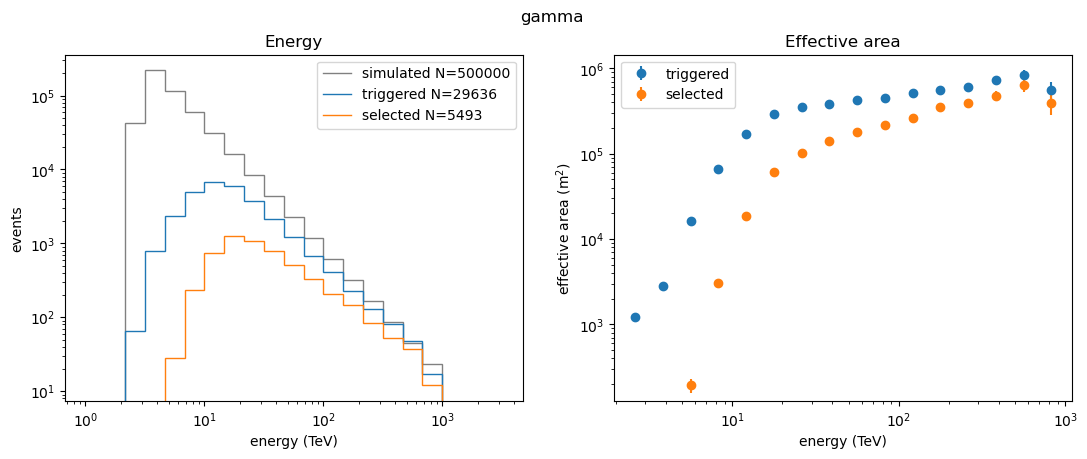

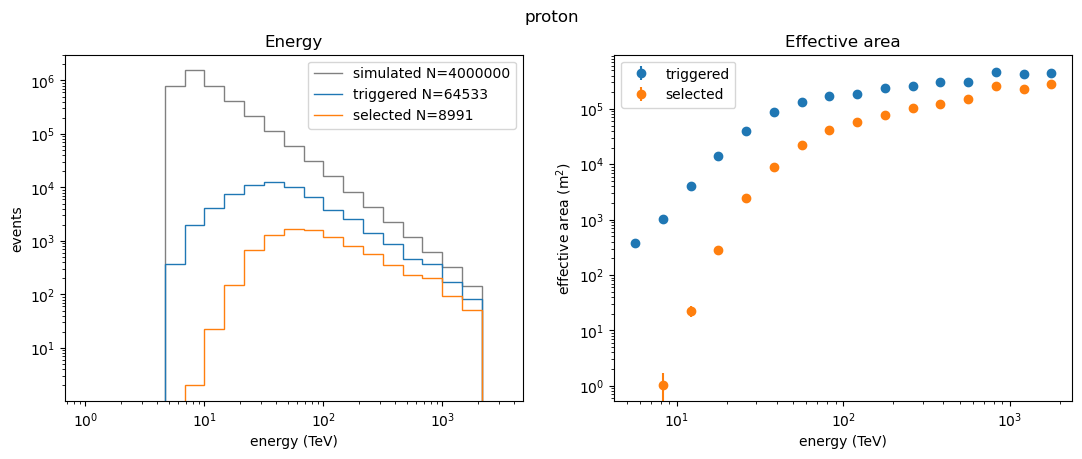

In [41]:
for label in SAMPLES:
    triggered = showers[label][showers[label].Event.isin(images[label].Event)]
    selected = showers[label][showers[label].Event.isin(arrays[label].Event)]
    fig = ps.plot_energies(runs[label], {"triggered": triggered, "selected": selected}, ENERGY_BINS)
    fig.suptitle(label)
    plt.show()

# Hillas parameters
Normalized histograms of every image, weighted by its shower's spectral weight.

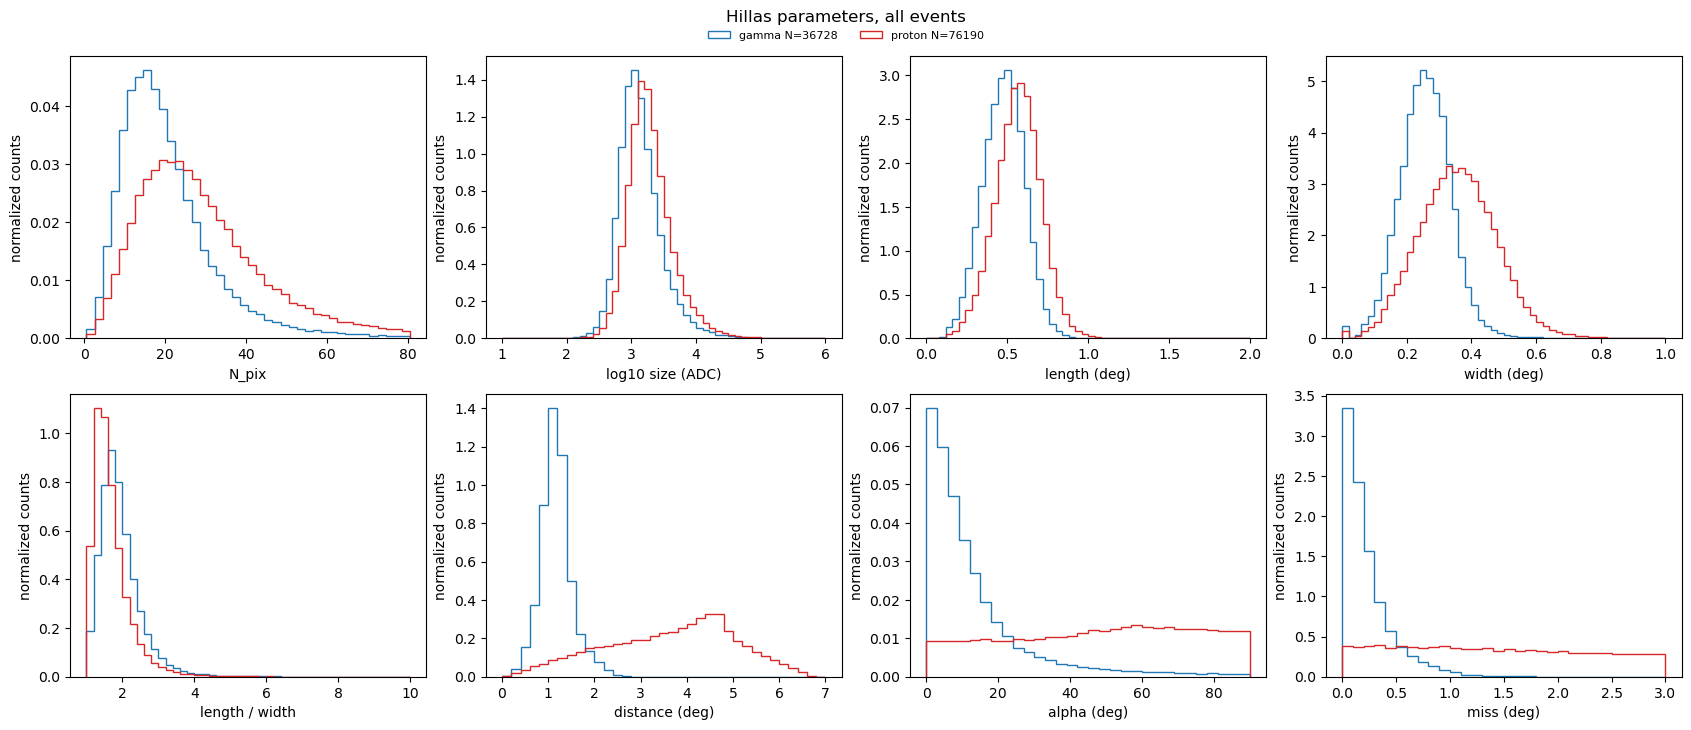

In [42]:
plot_hists(images, HILLAS_PARAMS, "Hillas parameters, all events")

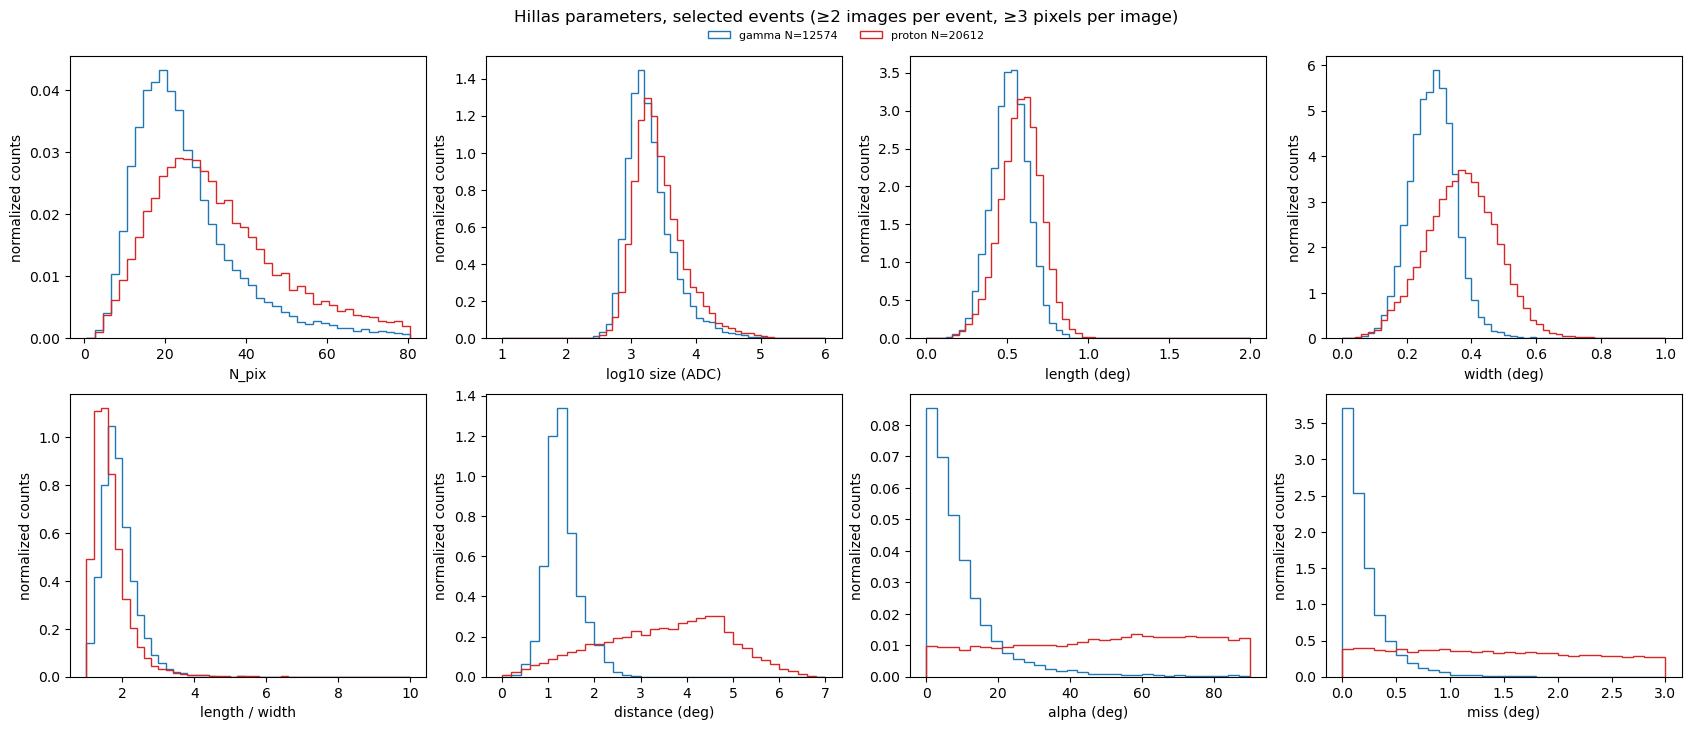

In [43]:
plot_hists(arrays, HILLAS_PARAMS, f"Hillas parameters, selected events ({SELECTED})")

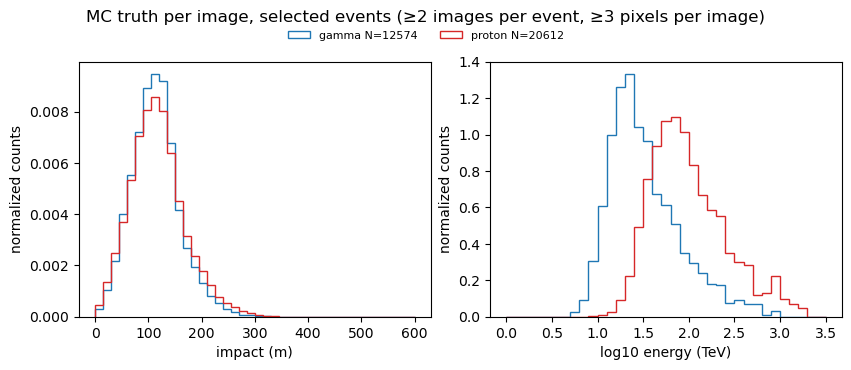

In [44]:
plot_hists(arrays, {
    "impact": ("impact (m)", np.linspace(0, 600, 41)),
    "log10_energy": ("log10 energy (TeV)", np.linspace(0, 3.5, 36)),
}, f"MC truth per image, selected events ({SELECTED})", n_cols=2)

In [45]:
pd.concat({label: array[["N_pix", "size", "length", "width", "length_width", "distance", "alpha", "impact_reco"]].describe() for label, array in arrays.items()}, axis=1)

gamma                                                           \
              N_pix           size        length         width  length_width   
count  12574.000000   12574.000000  12574.000000  12574.000000  12574.000000   
mean      26.341737    3189.799018      0.515984      0.281284      1.904232   
std       17.326065    6222.227648      0.113450      0.070575      0.500507   
min        3.000000      68.212780      0.096209      0.032687      1.011222   
25%       16.000000    1116.095351      0.441428      0.234061      1.578689   
50%       22.000000    1679.165269      0.517254      0.281642      1.820350   
75%       31.000000    2919.056269      0.592040      0.325777      2.128875   
max      296.000000  178221.682645      0.997469      0.807469      8.253421   

                                                       proton                 \
           distance         alpha   impact_reco         N_pix           size   
count  12574.000000  12574.000000  12574.000000  20612.000000   20612.000000   
mean       1.316327     10.117343    190.065164     37.202552    4863.804235   
std        0.362201     11.810725   1441.852974     25.560031   10349.678533   
min        0.219314      0.000101      0.029942      3.000000     168.222881   
25%        1.084935      2.926211     82.003246     22.000000    1458.048831   
50%        1.268635      6.578776    121.274450     31.000000    2290.101259   
75%        1.494100     12.699453    161.387717     45.000000    4286.436851   
max        3.544919     89.841823  91707.128680    345.000000  248944.122845   

                                                                             \
             length         width  length_width      distance         alpha   
count  20612.000000  20612.000000  20612.000000  20612.000000  20612.000000   
mean       0.583477      0.370257      1.675961      3.502196     48.075883   
std        0.128612      0.110603      0.521789      1.355928     25.584760   
min        0.132036      0.043701      1.004243      0.029787      0.005042   
25%        0.501261      0.295566      1.341915      2.503605     26.571501   
50%        0.587873      0.371634      1.556720      3.638871     50.262854   
75%        0.669282      0.443985      1.861472      4.546016     69.964778   
max        1.323388      0.916455     10.150011      6.695111     89.997499   

                      
         impact_reco  
count   20612.000000  
mean      336.423121  
std      3851.772868  
min         0.018676  
25%        84.296649  
50%       136.077675  
75%       193.595445  
max    195893.250830

## Profiles
Mean of one parameter in bins of another for the selected events, with its error.

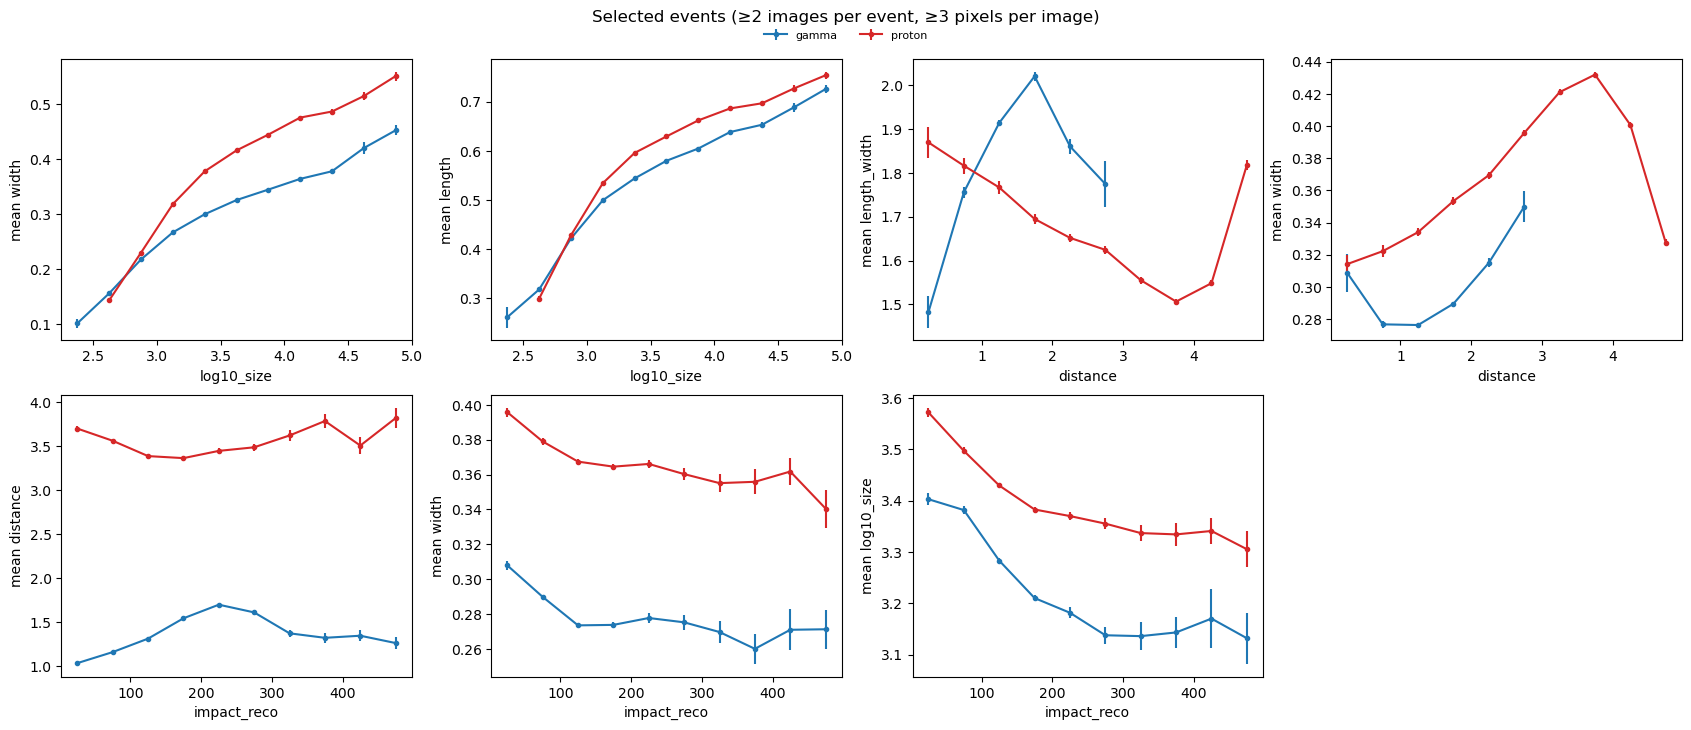

In [46]:
PROFILES = [ # (x, y, x bin edges): mean y in bins of x
    ("log10_size", "width", np.linspace(1.5, 5, 15)),
    ("log10_size", "length", np.linspace(1.5, 5, 15)),
    ("distance", "length_width", np.linspace(0, 5, 11)),
    ("distance", "width", np.linspace(0, 5, 11)),
    ("impact_reco", "distance", np.linspace(0, 500, 11)),
    ("impact_reco", "width", np.linspace(0, 500, 11)),
    ("impact_reco", "log10_size", np.linspace(0, 500, 11)),
]
plot_profiles(arrays, PROFILES, f"Selected events ({SELECTED})")

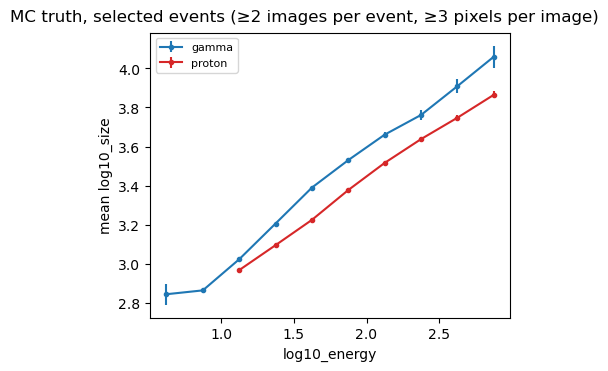

In [47]:
plot_profiles(arrays, [("log10_energy", "log10_size", np.linspace(0.5, 3, 11))], f"MC truth, selected events ({SELECTED})", n_cols=1)

# Mean scaled width and length
Lookup tables of the gammas' weighted mean and spread of width and length per bin of `LOOKUP_X` and `LOOKUP_Y`. Each
image's scaled width is (width - mean) / spread of its bin, and each event's mean scaled width (`mscw`) the mean over
its images; the same for length (`mscl`). Images outside the tables (or in bins with too few gammas) are left out. The
tables are made from the same gammas they are applied to.

In [48]:
def lookup_bins(images):
    """each image's (LOOKUP_X, LOOKUP_Y) bin, -1 outside LOOKUP_X_BINS, LOOKUP_Y_BINS"""
    return pd.DataFrame({
        "xi": pd.cut(images[LOOKUP_X], LOOKUP_X_BINS, labels=False).fillna(-1).astype(int),
        "yi": pd.cut(images[LOOKUP_Y], LOOKUP_Y_BINS, labels=False).fillna(-1).astype(int),
    })

def lookup_table(images, column, min_images=10):
    """weighted mean and standard deviation of column per (LOOKUP_X, LOOKUP_Y) bin with at least min_images images"""
    images = pd.concat([images[[column, "weight"]], lookup_bins(images)], axis=1).dropna()
    images = images[(images.xi >= 0) & (images.yi >= 0)]
    images = images.assign(wv=images.weight * images[column], wv2=images.weight * images[column]**2)
    sums = images.groupby(["xi", "yi"])[["weight", "wv", "wv2"]].sum()
    mean = sums.wv / sums.weight
    table = pd.DataFrame({"mean": mean, "std": np.sqrt((sums.wv2 / sums.weight - mean**2).clip(lower=0)), "n": images.groupby(["xi", "yi"]).size()})
    return table[table.n >= min_images]

def scaled_parameter(images, column, table):
    """each image's (column - mean) / std of its bin of table; NaN outside it"""
    bins = table.reindex(pd.MultiIndex.from_frame(lookup_bins(images)))
    with np.errstate(divide="ignore", invalid="ignore"):
        return (images[column].to_numpy() - bins["mean"].to_numpy()) / bins["std"].to_numpy()

def event_parameters(array):
    """
    one row per event: n_images, log10_total_size (of its images' summed size), max_distance (of its farthest
    image), weight, and mscw, mscl: the mean of its images' scaled width and length (images outside the
    lookup tables left out, NaN if all are)
    """
    array = array.assign(mscw=scaled_parameter(array, "width", tables["width"]), mscl=scaled_parameter(array, "length", tables["length"]))
    grouped = array.groupby("Event")
    return pd.DataFrame({
        "n_images": grouped.size(),
        "log10_total_size": np.log10(grouped["size"].sum()),
        "max_distance": grouped.distance.max(),
        "mscw": grouped.mscw.mean(),
        "mscl": grouped.mscl.mean(),
        "weight": grouped.weight.first(),
    })

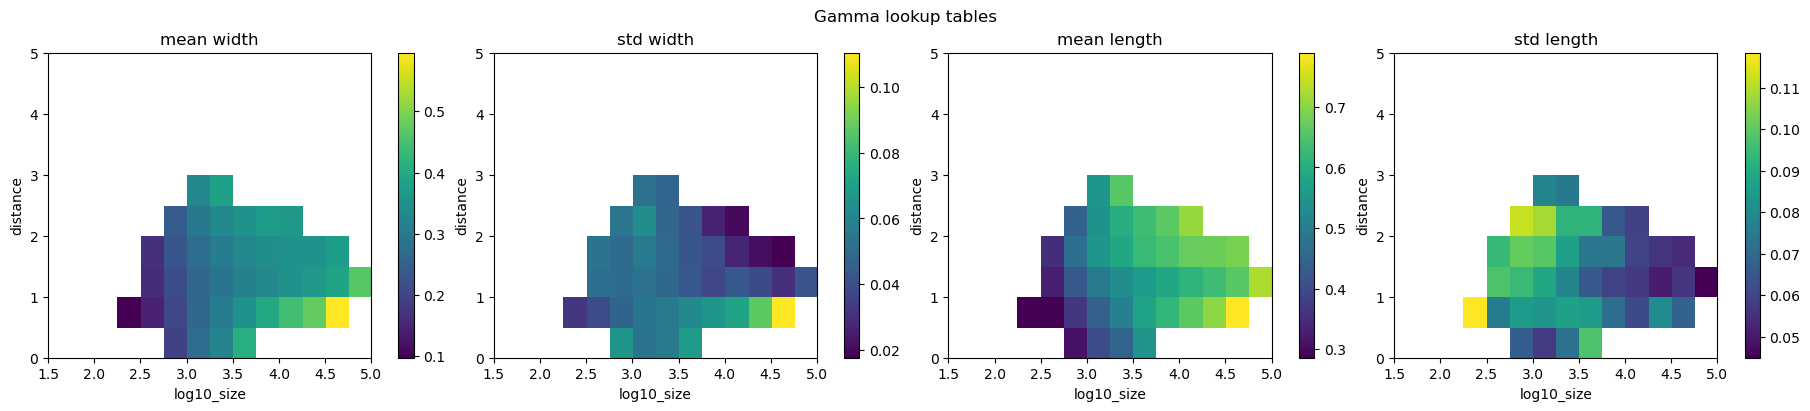

In [49]:
tables = {column: lookup_table(arrays["gamma"], column) for column in ["width", "length"]}

fig, axs = plt.subplots(1, 4, figsize=(18, 4), layout="constrained")
for ax, (column, key) in zip(axs, [(column, key) for column in tables for key in ("mean", "std")]):
    grid = tables[column][key].unstack().reindex(index=range(len(LOOKUP_X_BINS) - 1), columns=range(len(LOOKUP_Y_BINS) - 1))
    im = ax.imshow(grid.T, origin="lower", aspect="auto", extent=[LOOKUP_X_BINS[0], LOOKUP_X_BINS[-1], LOOKUP_Y_BINS[0], LOOKUP_Y_BINS[-1]])
    fig.colorbar(im, ax=ax)
    ax.set(xlabel=LOOKUP_X, ylabel=LOOKUP_Y, title=f"{key} {column}")
fig.suptitle("Gamma lookup tables")
plt.show()

# Reconstruction
Arrival directions (`heap.reconstruction`), and their θ² to the source: the gammas' mean true direction (`true_x`,
`true_y`, see `heap.process_simulation.camera_position()`). Each event's mean reconstructed impact distance (`mean_impact_reco`), and
`core_error`, the distance from the true core in the plane perpendicular to the pointing (`heap.process_simulation.tilted_core()`).

In [50]:
SOURCE_X, SOURCE_Y = showers["gamma"].true_x.mean(), showers["gamma"].true_y.mean()
print(f"source at ({SOURCE_X:.3f}, {SOURCE_Y:.3f}) deg, gammas' true directions within "
      f"{np.hypot(showers['gamma'].true_x - SOURCE_X, showers['gamma'].true_y - SOURCE_Y).max():.2f} deg of it")

events = {}
for label, array in arrays.items():
    e = event_parameters(array).join(showers[label].set_index("Event")[["energy"]])
    e["log10_energy"] = np.log10(e.energy)
    e = e.join(reconstruct_directions(array).set_index("Event")[["Xoffset", "Yoffset"]])
    e["theta2"] = (e.Xoffset - SOURCE_X)**2 + (e.Yoffset - SOURCE_Y)**2
    e = e.join(cores[label].set_index("Event")).join(array.groupby("Event").impact_reco.mean().rename("mean_impact_reco"))
    true_x, true_y = ps.tilted_core(showers[label].set_index("Event").loc[e.index], runs[label].alt.mean(), runs[label].az.mean())
    e["core_error"] = np.hypot(e.core_x - true_x, e.core_y - true_y)
    events[label] = e
    print(f"{label}: {len(e)} events, {e.theta2.notna().sum()} directions and {e.core_x.notna().sum()} cores reconstructed, "
          f"core error median {e.core_error.median():.0f} m")

source at (-0.000, 0.000) deg, gammas' true directions within 0.00 deg of it
gamma: 5493 events, 5493 directions and 5493 cores reconstructed, core error median 31 m
proton: 8991 events, 8991 directions and 8991 cores reconstructed, core error median 59 m


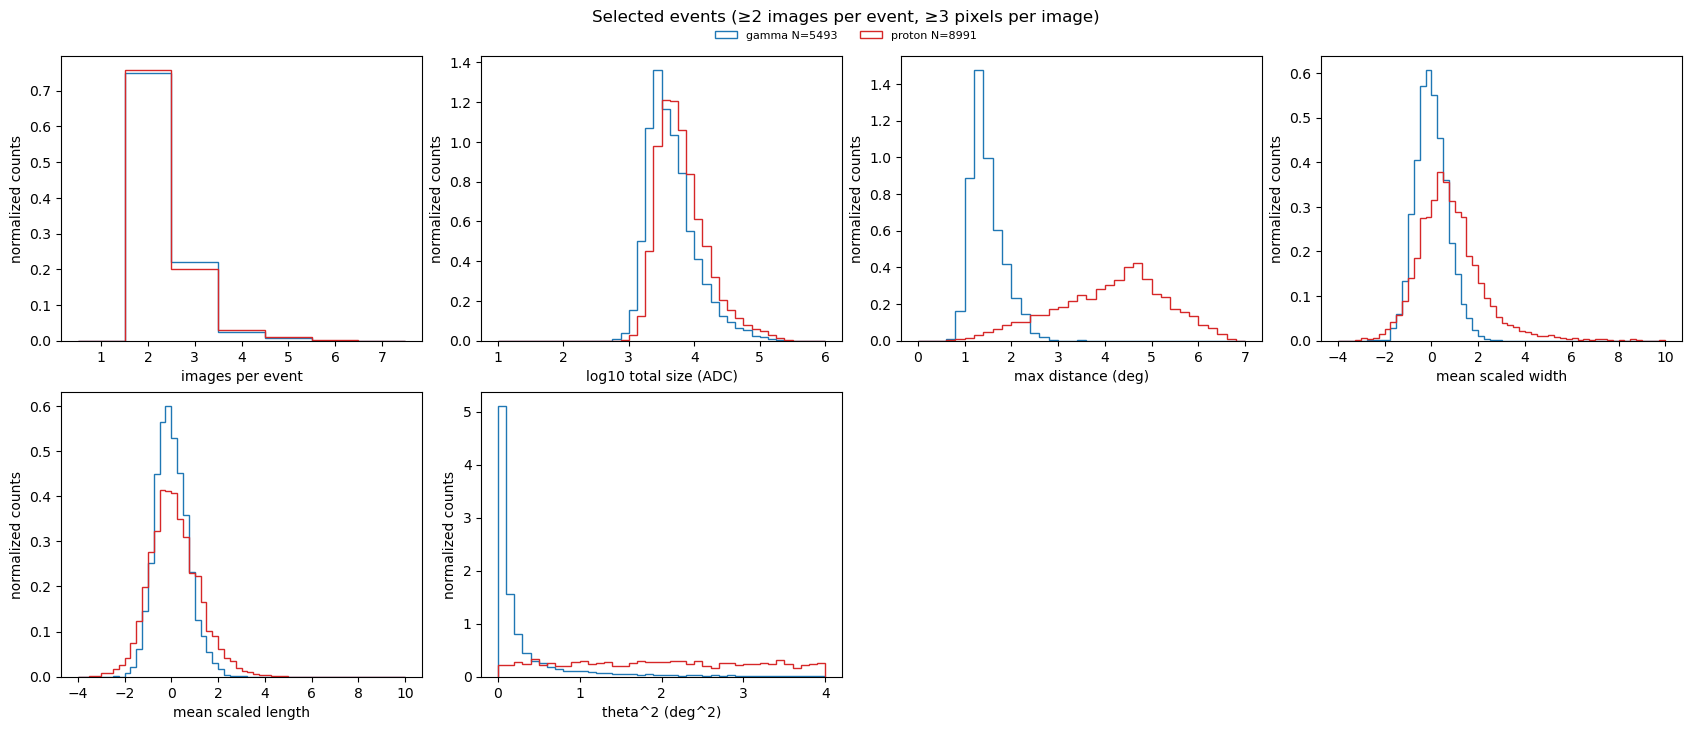

In [51]:
plot_hists(events, EVENT_PARAMS, f"Selected events ({SELECTED})")

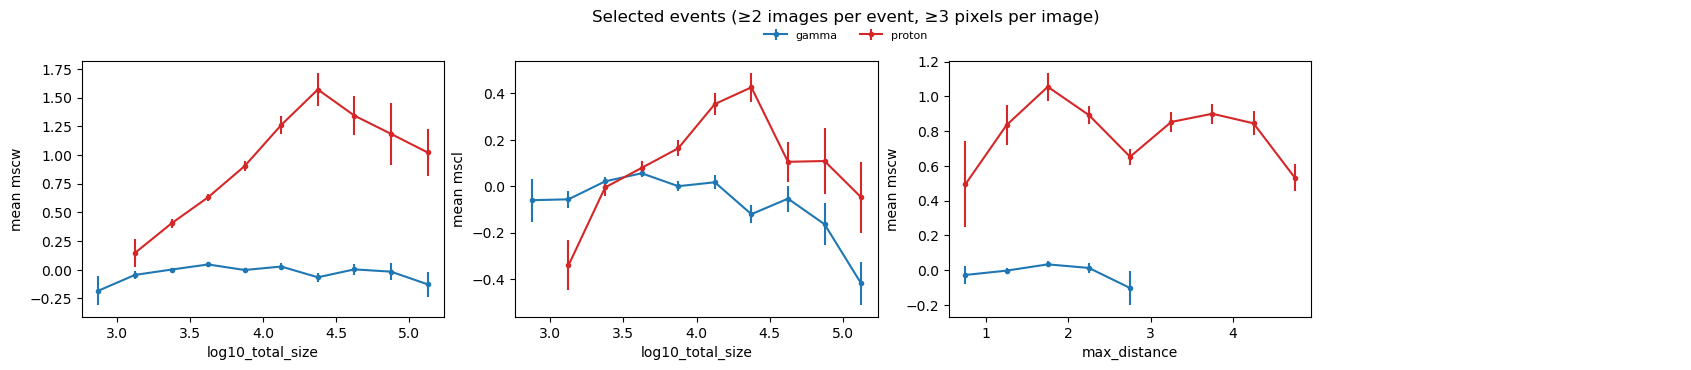

In [52]:
plot_profiles(events, [
    ("log10_total_size", "mscw", np.linspace(2.5, 5.5, 13)),
    ("log10_total_size", "mscl", np.linspace(2.5, 5.5, 13)),
    ("max_distance", "mscw", np.linspace(0, 5, 11)),
], f"Selected events ({SELECTED})")

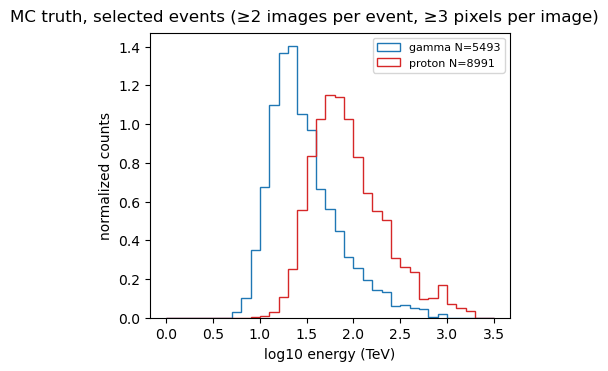

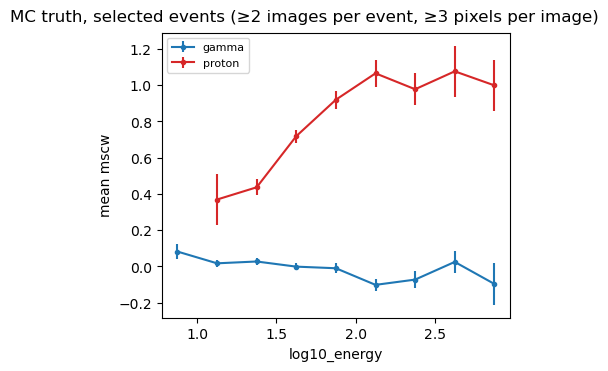

In [53]:
plot_hists(events, {"log10_energy": ("log10 energy (TeV)", np.linspace(0, 3.5, 36))}, f"MC truth, selected events ({SELECTED})", n_cols=1)
plot_profiles(events, [("log10_energy", "mscw", np.linspace(0.5, 3, 11))], f"MC truth, selected events ({SELECTED})", n_cols=1)

## Cores
Each image's reconstructed against true impact distance, and the core error's 68% containment per bin of true energy.
Near-parallel image axes (mostly two-image events) put a few cores kilometres away.

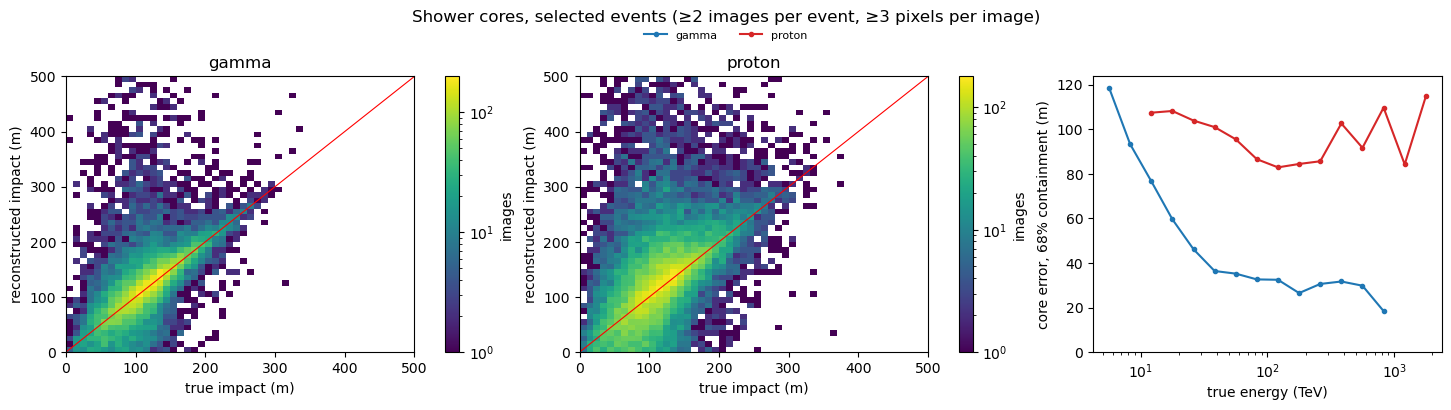

In [54]:
fig, axs = plt.subplots(1, len(arrays) + 1, figsize=(4.8*(len(arrays) + 1), 4), squeeze=False, layout="constrained")
impact_bins = np.linspace(0, 500, 51)
for ax, (label, array) in zip(axs[0], arrays.items()):
    *_, im = ax.hist2d(array.impact, array.impact_reco, bins=impact_bins, norm=LogNorm())
    fig.colorbar(im, ax=ax, label="images")
    ax.plot(impact_bins[[0, -1]], impact_bins[[0, -1]], "r-", lw=0.8)
    ax.set(xlabel="true impact (m)", ylabel="reconstructed impact (m)", title=label)
ax = axs[0, -1]
centers = np.sqrt(ENERGY_BINS[1:] * ENERGY_BINS[:-1])
for label, e in events.items():
    grouped = e.core_error.groupby(pd.cut(e.energy, ENERGY_BINS), observed=False)
    containment = grouped.quantile(0.68).where(grouped.size() >= 10)
    ax.plot(centers, containment.to_numpy(), "o-", ms=3, color=COLORS[label], label=label)
ax.set(xscale="log", ylim=(0, None), xlabel="true energy (TeV)", ylabel="core error, 68% containment (m)")
legend_and_title(fig, ax, axs.size, f"Shower cores, selected events ({SELECTED})")
plt.show()

# Cuts
How well a single cut separates the gammas from the protons: each one's weighted fraction kept against the cut, and
the quality factor Q = (gammas kept) / sqrt(protons kept), the significance's improvement for a background-dominated
source, with the best cut that keeps at least 10% of the gammas. Fractions are of the events with a value: events
without a mean scaled width (all their images outside the lookup table) are left out of its scan.

`theta2`, `max_distance`, `alpha` and `miss` separate by direction (point-like gammas against diffuse protons),
`mscw`, `mscl`, `width` and `length` by shape.

In [55]:
def cut_efficiencies(gammas, protons, column, keep="below", n_cuts=200):
    """the weighted fraction of the gammas and protons with a value of column that a cut on it keeps, and Q"""
    gammas, protons = gammas.dropna(subset=[column]), protons.dropna(subset=[column])
    cuts = np.unique(np.quantile(pd.concat([gammas[column], protons[column]]), np.linspace(0.001, 0.999, n_cuts)))
    def kept(sample):
        values = sample[column].to_numpy()[None, :]
        passed = values < cuts[:, None] if keep == "below" else values > cuts[:, None]
        return (passed * sample.weight.to_numpy()).sum(axis=1) / sample.weight.sum()
    eff = pd.DataFrame({"cut": cuts, "gamma": kept(gammas), "proton": kept(protons)})
    with np.errstate(divide="ignore"):
        eff["Q"] = eff.gamma / np.sqrt(eff.proton)
    return eff

def plot_cut_scan(gammas, protons, cuts, title="", min_gamma=0.1):
    """
    cut_efficiencies() of each column of cuts ({column: (keep, plotted range)}); returns the best cut on each, the one
    with the highest Q among those keeping at least min_gamma of the gammas
    """
    fig, axs = plt.subplots(1, len(cuts), figsize=(4.5*len(cuts), 3.8), squeeze=False, layout="constrained")
    best = {}
    for ax, (column, (keep, lim)) in zip(axs[0], cuts.items()):
        eff = cut_efficiencies(gammas, protons, column, keep)
        ok = eff[(eff.gamma >= min_gamma) & (eff.proton > 0)]
        best[column] = {"keep": keep} | ok.loc[ok.Q.idxmax()].to_dict()
        ax.plot(eff.cut, eff.gamma, color=COLORS["gamma"], label="gammas kept")
        ax.plot(eff.cut, eff.proton, color=COLORS["proton"], label="protons kept")
        ax.axvline(best[column]["cut"], color="grey", ls=":")
        q_ax = ax.twinx()
        q_ax.plot(eff.cut, eff.Q, "k--")
        q_ax.set(ylabel="Q (dashed)", ylim=(0, None))
        ax.set(xlabel=column, ylabel="fraction kept", xlim=lim, ylim=(0, 1.02), title=f"keep {keep}")
    legend_and_title(fig, axs[0, 0], len(cuts), title)
    plt.show()
    return pd.DataFrame(best).T

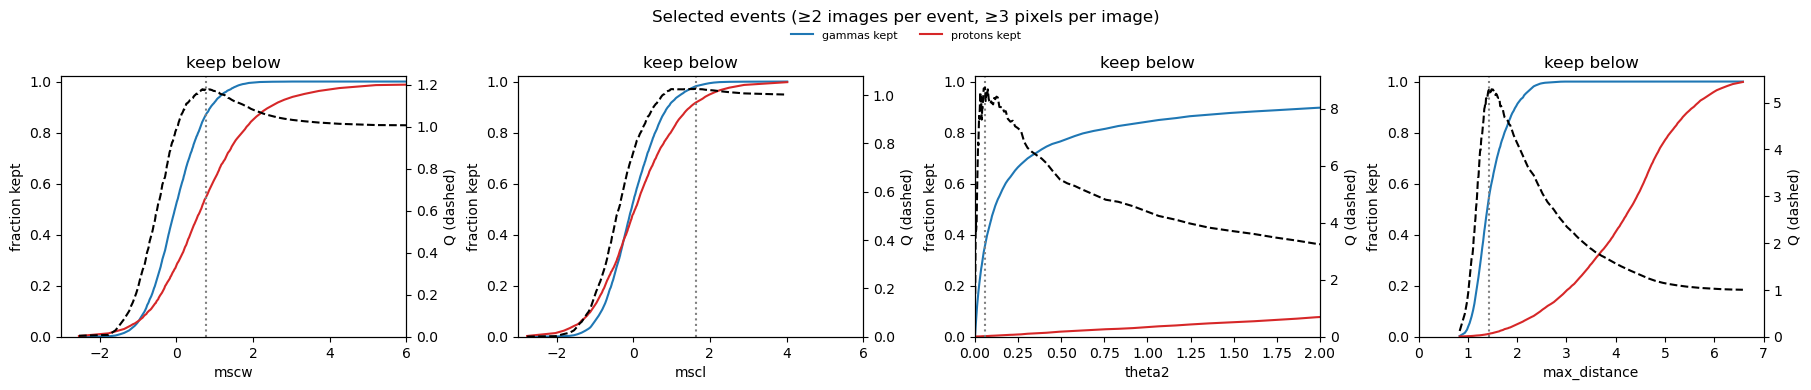

,keep,cut,gamma,proton,Q
mscw,below,0.767288,0.870016,0.543864,1.179729
mscl,below,1.632075,0.981795,0.917475,1.025
theta2,below,0.058034,0.357,0.001668,8.7403
max_distance,below,1.434319,0.553432,0.0109,5.300965


In [56]:
EVENT_CUTS = { # column: (keep, plotted range)
    "mscw": ("below", (-3, 6)),
    "mscl": ("below", (-3, 6)),
    "theta2": ("below", (0, 2)),
    "max_distance": ("below", (0, 7)),
}
plot_cut_scan(events["gamma"], events["proton"], EVENT_CUTS, f"Selected events ({SELECTED})")

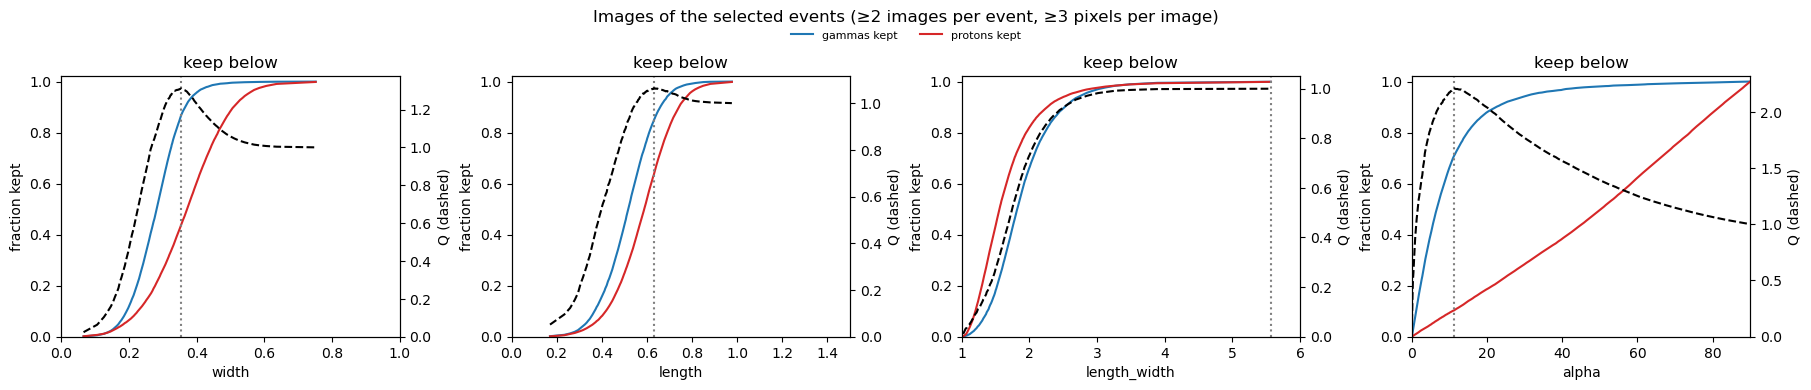

,keep,cut,gamma,proton,Q
width,below,0.354409,0.869731,0.439986,1.311189
length,below,0.629784,0.846191,0.631962,1.064444
length_width,below,5.567689,0.999205,0.998836,0.999787
alpha,below,11.18854,0.708048,0.10261,2.210384


In [57]:
# per image instead of per event
IMAGE_CUT_SCAN = { # column: (keep, plotted range)
    "width": ("below", (0, 1)),
    "length": ("below", (0, 1.5)),
    "length_width": ("below", (1, 6)),
    "alpha": ("below", (0, 90)),
}
plot_cut_scan(arrays["gamma"], arrays["proton"], IMAGE_CUT_SCAN, f"Images of the selected events ({SELECTED})")

In [58]:
# a combination of cuts, as a pandas query on the events; events without a value (NaN) fail it
SELECTION = "mscw < 1 and theta2 < 0.2"
kept = {label: e.query(SELECTION).weight.sum() / e.weight.sum() for label, e in events.items()}
print(f"{SELECTION}: {kept['gamma']:.1%} of gammas, {kept['proton']:.2%} of protons kept, Q = {kept['gamma'] / np.sqrt(kept['proton']):.2f}")

mscw < 1 and theta2 < 0.2: 58.6% of gammas, 0.48% of protons kept, Q = 8.48


# BDT
A gradient-boosted decision tree (`sklearn.ensemble.HistGradientBoostingClassifier`) separating gammas from protons
with the event parameters in `FEATURES`, trained on half of the events and tested on the other half. Each production's
spectral weights are scaled so both sum to 1. The direction (`theta2`, and `max_distance`, which mostly tells point-like
gammas from diffuse protons) is left out, to stay a separate cut, and so are events missing a feature (e.g. a mean
scaled width outside the lookup table, which also says where the images are).

In [59]:
FEATURES = ["mscw", "mscl", "log10_total_size", "n_images"]

X = pd.concat(events, names=["label"]).reset_index().dropna(subset=FEATURES)
X["is_gamma"] = (X.label == "gamma").astype(int)
X["class_weight"] = X.weight / X.groupby("label").weight.transform("sum")
train, test = train_test_split(X, test_size=0.5, stratify=X.is_gamma, random_state=0)

bdt = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=0)
bdt.fit(train[FEATURES], train.is_gamma, sample_weight=train.class_weight)
test = test.assign(score=bdt.predict_proba(test[FEATURES])[:, 1])
gammas, protons = test[test.is_gamma == 1], test[test.is_gamma == 0]
print(f"{len(X)} of {sum(len(e) for e in events.values())} events with every feature: {len(train)} training, {len(test)} test, "
      f"test AUC {roc_auc_score(test.is_gamma, test.score, sample_weight=test.class_weight):.3f}")

9722 of 14484 events with every feature: 4861 training, 4861 test, test AUC 0.762


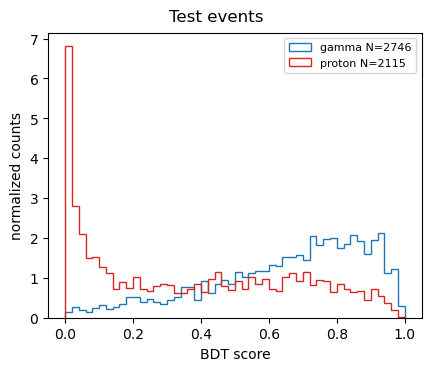

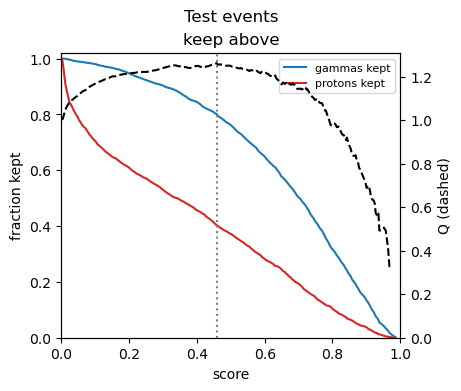

,keep,cut,gamma,proton,Q
score,above,0.458321,0.801165,0.402837,1.262285


In [60]:
plot_hists({"gamma": gammas, "proton": protons}, {"score": ("BDT score", np.linspace(0, 1, 51))}, "Test events", n_cols=1)
plot_cut_scan(gammas, protons, {"score": ("above", (0, 1))}, "Test events")

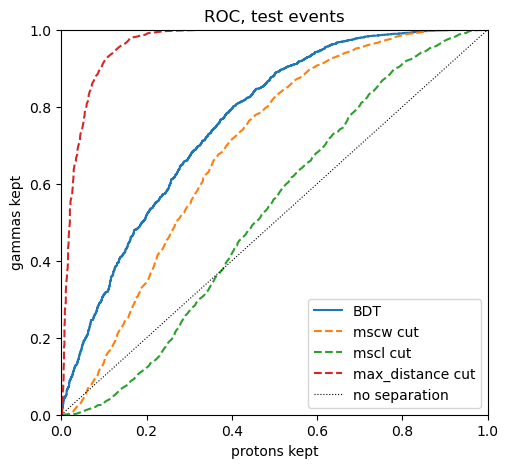

In [61]:
fpr, tpr, _ = roc_curve(test.is_gamma, test.score, sample_weight=test.class_weight)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(fpr, tpr, label="BDT")
for column in ["mscw", "mscl", "max_distance"]: # single cuts, for comparison
    eff = cut_efficiencies(gammas, protons, column)
    ax.plot(eff.proton, eff.gamma, ls="--", label=f"{column} cut")
ax.plot([0, 1], [0, 1], "k:", lw=0.8, label="no separation")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="protons kept", ylabel="gammas kept", title="ROC, test events")
ax.legend()
plt.show()

In [62]:
# feature importance: how much the test AUC drops when one feature is shuffled
importance = permutation_importance(bdt, test[FEATURES], test.is_gamma, sample_weight=test.class_weight,
                                    scoring="roc_auc", n_repeats=10, random_state=0)
pd.DataFrame({"AUC drop": importance.importances_mean, "std": importance.importances_std}, index=FEATURES).sort_values("AUC drop", ascending=False)

,AUC drop,std
mscw,0.158564,0.008799
mscl,0.058330,0.004725
log10_total_size,0.052283,0.003003
n_images,0.010171,0.001617


# Energy
A gradient-boosted regression (`sklearn.ensemble.HistGradientBoostingRegressor`) of each gamma event's log10 true
energy from the event parameters in `ENERGY_FEATURES`, including the reconstructed core distance (`mean_impact_reco`),
and each telescope's log10 size (NaN where it has no image, which the trees handle), all of which the data also has.
Trained on half of the selected gammas, unweighted, and tested on the other half.

Per bin of true energy, the bias is the median of E_reco / E_true - 1 and the resolution half its 16-84% range.

In [63]:
ENERGY_FEATURES = ["log10_total_size", "n_images", "max_distance", "mscw", "mscl", "mean_impact_reco"]

tel_sizes = arrays["gamma"].pivot_table(index="Event", columns="Telescope", values="log10_size").add_prefix("log10_size_")
gamma_events = events["gamma"].join(tel_sizes)
columns = ENERGY_FEATURES + list(tel_sizes.columns)
e_train, e_test = train_test_split(gamma_events.dropna(subset=["log10_energy"]), test_size=0.5, random_state=0)

regressor = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, random_state=0)
regressor.fit(e_train[columns], e_train.log10_energy)
energy_reco = pd.Series(10**regressor.predict(e_test[columns]), index=e_test.index)
print(f"{len(e_train)} training, {len(e_test)} test gamma events; per-telescope sizes {list(tel_sizes.columns)}")

2746 training, 2747 test gamma events; per-telescope sizes ['log10_size_T1', 'log10_size_T2', 'log10_size_T3', 'log10_size_T4', 'log10_size_T5', 'log10_size_T6', 'log10_size_T7']


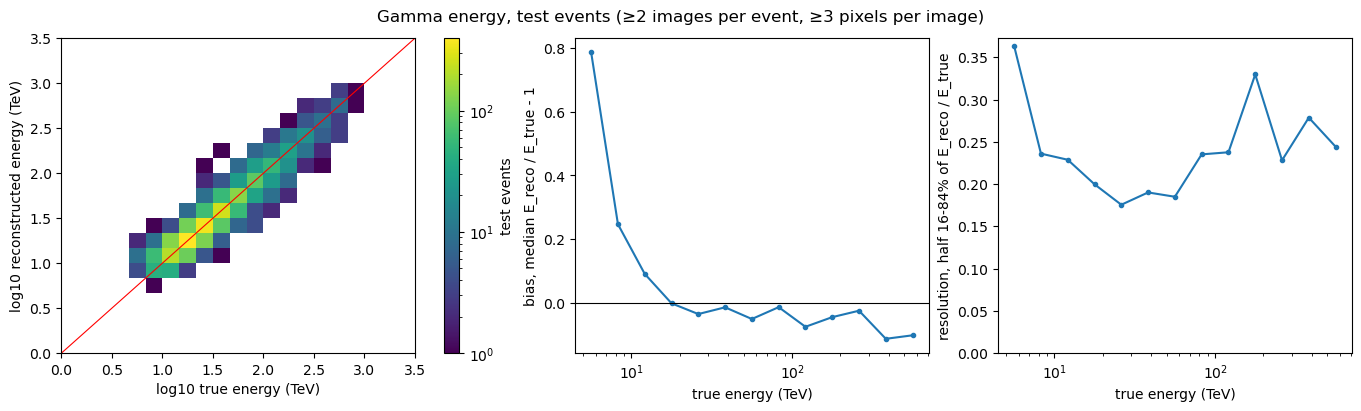

In [64]:
def bias_resolution(e_true, e_reco, bins, min_entries=10):
    """per bin of e_true: the median of e_reco / e_true - 1 (bias) and half its 16-84% range (resolution), NaN under min_entries"""
    grouped = (e_reco / e_true - 1).groupby(pd.cut(e_true, bins), observed=False)
    q = grouped.quantile([0.16, 0.5, 0.84]).unstack()
    result = pd.DataFrame({"bias": q[0.5], "resolution": (q[0.84] - q[0.16]) / 2})
    result[grouped.size() < min_entries] = np.nan
    return result.reset_index(drop=True)

log_bins = np.log10(ENERGY_BINS)
centers = np.sqrt(ENERGY_BINS[1:] * ENERGY_BINS[:-1])
br = bias_resolution(e_test.energy, energy_reco, ENERGY_BINS)
fig, axs = plt.subplots(1, 3, figsize=(13.5, 4), layout="constrained")
*_, im = axs[0].hist2d(e_test.log10_energy, np.log10(energy_reco), bins=log_bins, norm=LogNorm())
fig.colorbar(im, ax=axs[0], label="test events")
axs[0].plot(log_bins[[0, -1]], log_bins[[0, -1]], "r-", lw=0.8)
axs[0].set(xlabel="log10 true energy (TeV)", ylabel="log10 reconstructed energy (TeV)")
axs[1].plot(centers, br.bias, "o-", ms=3)
axs[1].axhline(0, color="k", lw=0.8)
axs[1].set(xscale="log", xlabel="true energy (TeV)", ylabel="bias, median E_reco / E_true - 1")
axs[2].plot(centers, br.resolution, "o-", ms=3)
axs[2].set(xscale="log", ylim=(0, None), xlabel="true energy (TeV)", ylabel="resolution, half 16-84% of E_reco / E_true")
fig.suptitle(f"Gamma energy, test events ({SELECTED})")
plt.show()

In [65]:
# feature importance: how much the test R² of log10 energy drops when one feature is shuffled
importance = permutation_importance(regressor, e_test[columns], e_test.log10_energy, n_repeats=10, random_state=0)
pd.DataFrame({"R² drop": importance.importances_mean, "std": importance.importances_std}, index=columns).sort_values("R² drop", ascending=False)

,R² drop,std
log10_total_size,1.080953,0.025311
max_distance,0.128049,0.007659
mean_impact_reco,0.076305,0.002718
n_images,0.016593,0.000654
mscl,0.009473,0.001932
log10_size_T1,0.007091,0.000288
log10_size_T7,0.005203,0.000480
log10_size_T6,0.004597,0.000962
log10_size_T4,0.004256,0.000615
log10_size_T3,0.003334,0.000985
